In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
cwd = Path.cwd()

In [2]:
model_number = 4
trial_number = 1

trial_dir = f"model_v{model_number}_test_{trial_number}"

DATA_DIR = cwd.parent / "test" / trial_dir / "test.csv"

In [3]:
df = pd.read_csv(DATA_DIR, low_memory=False)
df.head(5)

,epoch,train_bg_rmse,train_bg_mae,train_bg_r2,train_fe_rmse,train_fe_mae,train_fe_r2,test_bg_rmse,test_bg_mae,test_bg_r2,test_fe_rmse,test_fe_mae,test_fe_r2,loss
0,1,1.109617,0.873134,0.143044,0.780010,0.605292,0.248479,1.121511,0.893717,0.052920,0.782901,0.619253,0.280333,1.318020
1,2,1.090204,0.876133,0.172768,0.819728,0.657336,0.169995,1.080303,0.861648,0.121239,0.915298,0.745284,0.016345,0.503451
2,3,0.793981,0.614718,0.561235,0.677279,0.532099,0.433400,0.799572,0.630423,0.518613,0.750450,0.607002,0.338756,0.375776
3,4,0.770186,0.602741,0.587139,0.732830,0.568063,0.336642,0.790840,0.634256,0.529069,0.805115,0.650609,0.238914,0.328645
4,5,0.749762,0.566650,0.608747,0.718774,0.557353,0.361845,0.757422,0.591908,0.568028,0.748956,0.601098,0.341387,0.312351


In [4]:
import matplotlib.pyplot as plt

In [5]:
def graph_metric(metric, split="both"):
    """
    Plot train/test metrics for band gap and formation energy.

    Args:
        df      : DataFrame with epoch_results rows
        metric  : 'mae', 'rmse', or 'r2'
        split   : 'train', 'test', or 'both' (default)
    """
    metric = metric.lower()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    targets = [
        ("bg", "Band Gap",         "royalblue",   "cornflowerblue"),
        ("fe", "Formation Energy",  "forestgreen", "mediumseagreen"),
    ]

    for ax, (key, title, train_color, test_color) in zip(axes, targets):
        if split in ("train", "both"):
            ax.plot(
                df["epoch"], df[f"train_{key}_{metric}"],
                label=f"Train {metric.upper()}",
                color=train_color, linewidth=2, linestyle="--"
            )
        if split in ("test", "both"):
            ax.plot(
                df["epoch"], df[f"test_{key}_{metric}"],
                label=f"Test {metric.upper()}",
                color=test_color, linewidth=2
            )

        ax.set_title(f"{title} ({metric.upper()})", fontsize=14)
        ax.set_xlabel("Epoch", fontsize=12)
        ax.set_ylabel(metric.upper(), fontsize=12)
        ax.grid(True, linestyle="--", alpha=0.7)
        ax.legend()

    plt.suptitle(f"Model Performance — {metric.upper()}", fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


def graph_loss():
    """
    Plot the training loss curve.

    Args:
        df : DataFrame with epoch_results rows
    """
    fig, ax = plt.subplots(figsize=(8, 5))

    ax.plot(df["epoch"], df["loss"], color="darkorange", linewidth=2, label="Train Loss")
    ax.set_title("Training Loss", fontsize=14)
    ax.set_xlabel("Epoch", fontsize=12)
    ax.set_ylabel("Loss", fontsize=12)
    ax.grid(True, linestyle="--", alpha=0.7)
    ax.legend()

    plt.tight_layout()
    plt.show()

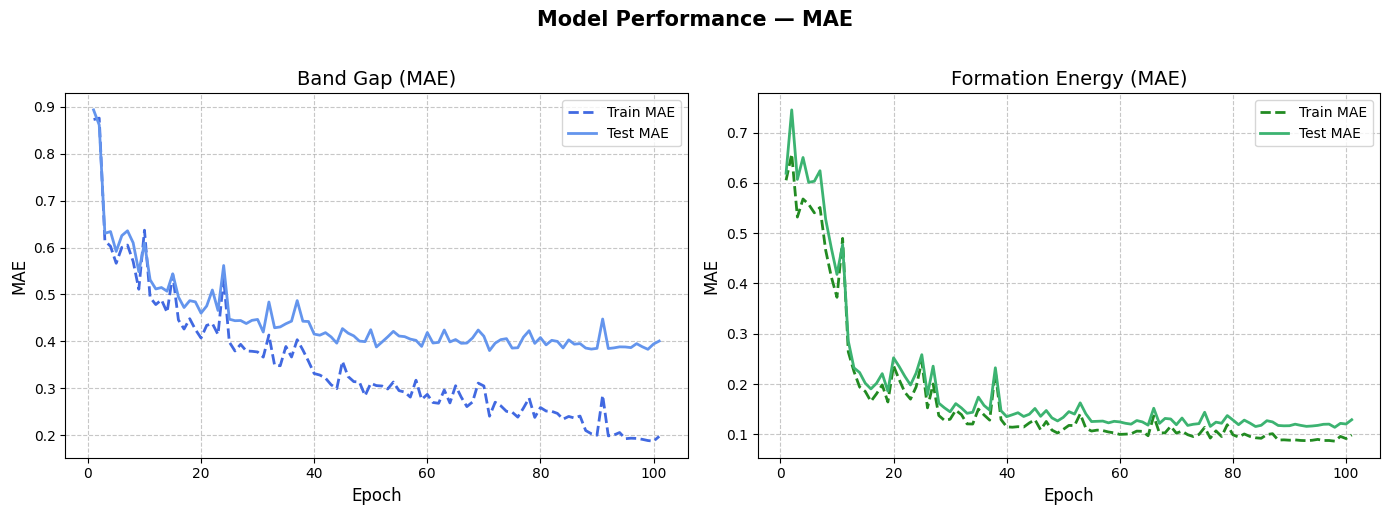

In [6]:
graph_metric('mae')

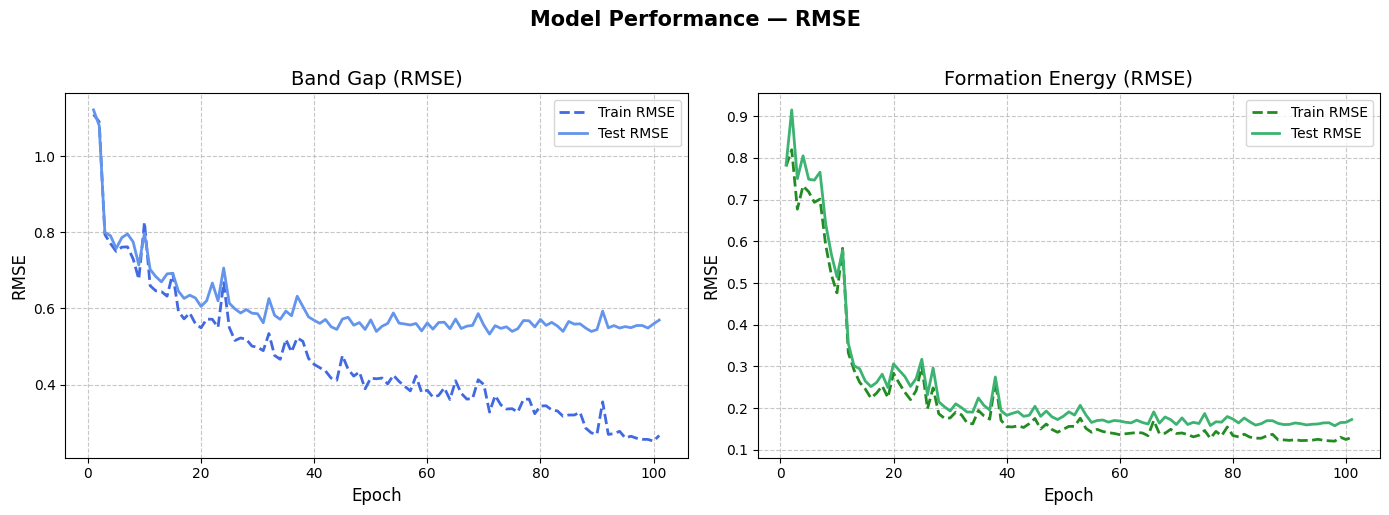

In [7]:
graph_metric('rmse')

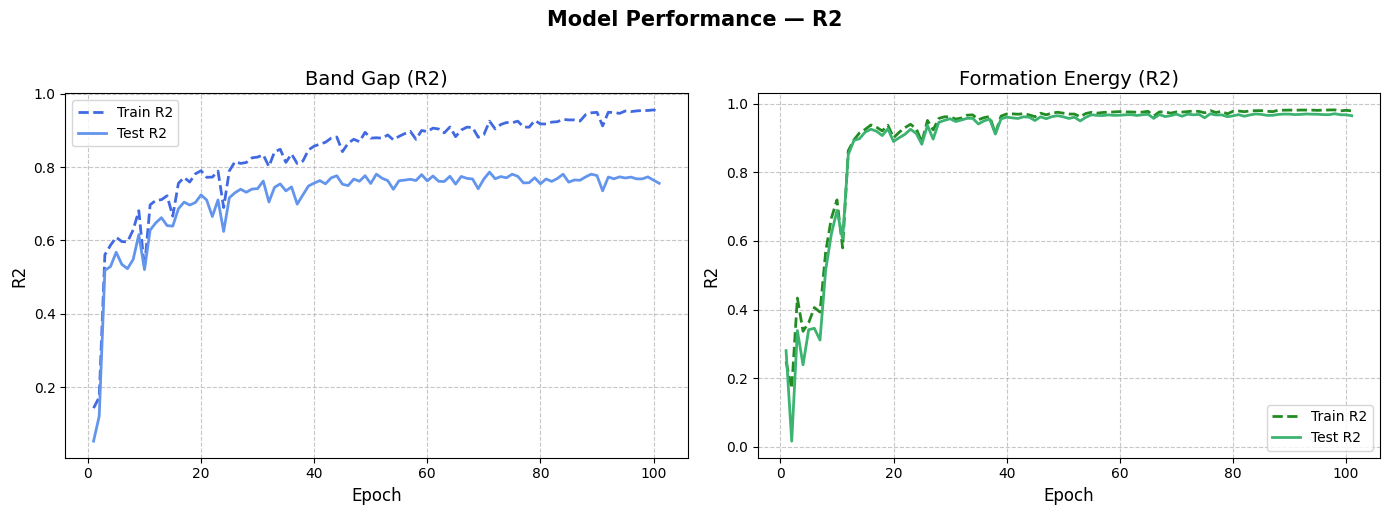

In [8]:
graph_metric('r2')

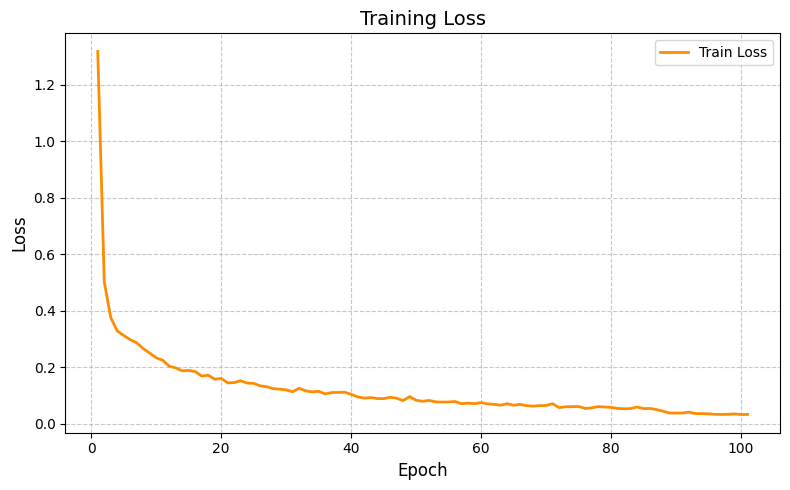

In [9]:
graph_loss()